In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [40]:
df = load_diabetes(as_frame=True)
X = df.data
y = df.target

print(X.shape)
print(y.shape)

(442, 10)
(442,)


In [41]:
display(X.head())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [42]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=0)

In [43]:
base_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=0)
base_model.fit(X_train, y_train)

y_pred_base = base_model.predict(X_test)
print("MSE: ", mean_squared_error(y_test, y_pred_base))
print("RMSE: ", np.sqrt(mean_squared_error(y_test, y_pred_base)))
print("R2 Score: ", r2_score(y_test, y_pred_base))

MSE:  4071.9510461055215
RMSE:  63.811840955307986
R2 Score:  0.20592648398710256


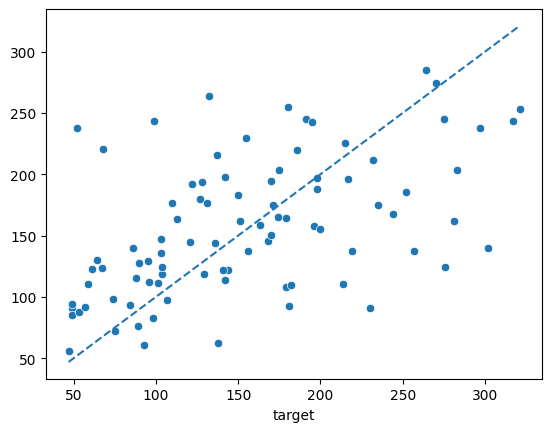

In [44]:
sns.scatterplot(x = y_test, y = y_pred_base)
low = min(y_test.min(), y_pred_base.min())
high = max(y_test.max(), y_pred_base.max())
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")


In [45]:
param_grid = {
    "n_estimators": [50, 100, 125],
    "max_depth" : [1, 2, 3, 4, 5, None],
    "learning_rate" : [0.05, 0.1],
    "subsample": [0.8, 1.0]
}

In [46]:
grid = GridSearchCV(
    GradientBoostingRegressor(random_state=0),
    cv = 5,
    scoring="neg_root_mean_squared_error",
    param_grid=param_grid,
    n_jobs=1
)

In [47]:
grid.fit(X_train, y_train)
print("Best Parameters: ", grid.best_params_)
print("Best CV RMSE: ", round(-grid.best_score_,2))

Best Parameters:  {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
Best CV RMSE:  54.66


In [48]:
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)

print("Base Test RMSE: ", round(np.sqrt(mean_squared_error(y_test, y_pred_base)), 2))
print("Best Test RMSE: ", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 2))
print("Tuned test R2: ", round(r2_score(y_test, y_pred_best), 3))

Base Test RMSE:  63.81
Best Test RMSE:  60.03
Tuned test R2:  0.297


In [51]:
imp = pd.Series(best_model.feature_importances_, index = X_train.columns)
imp

age    0.027987
sex    0.012318
bmi    0.334613
bp     0.089416
s1     0.018851
s2     0.028696
s3     0.064159
s4     0.006835
s5     0.381020
s6     0.036106
dtype: float64

<Axes: >

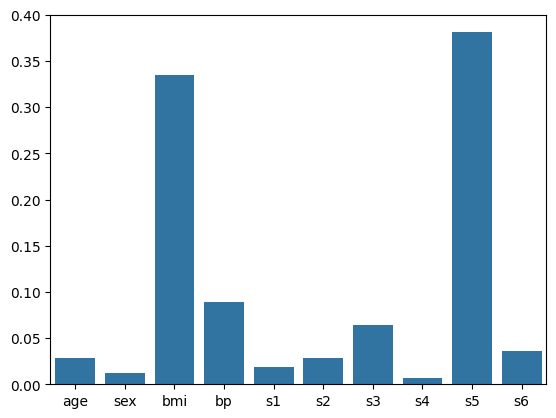

In [52]:
sns.barplot(data=imp)